# Explore the expense data with one line on the purpose.

## 1. Imports, Data, and Plot Style


In [1]:
# 1. Imports, data, and plot style
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import pandas as pd
import yaml
import seaborn as sns

from expense_agent.data import load_claims, load_dataset
from expense_agent.paths import GENERATED_DIR, POLICY_PATH
from expense_agent.policy import cap_usage, load_policy

DATE_COLS = ["expense_date", "submitted_date"]
POLICY = load_policy(POLICY_PATH)

claims = load_claims(GENERATED_DIR) # what the agent sees: no labels
labeled = load_dataset(GENERATED_DIR) # with answer key: section 5 only
for frame in (claims, labeled):
    frame[DATE_COLS] = frame[DATE_COLS].apply(pd.to_datetime)
history = pd.read_csv(
    GENERATED_DIR / "spend_history.csv", parse_dates=["week_start"]
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 4.5)

assert len(claims) == len(labeled), "Label join lost rows"
assert "violation_type" not in claims.columns, "Labels leaked into claims"
print(
    f"claims: {claims.shape} | labeled: {labeled.shape} | "
    f"history: {history.shape}"
)


claims: (330, 26) | labeled: (330, 32) | history: (780, 3)


## 2; Data Profile (data dictionary)

In [2]:
# 2 Data profile: one row per column
REQUIRED = [
    "claim_id",
    "report_id",
    "employee_id",
    "department",
    "expense_date",
    "submitted_date",
    "category",
    "amount",
    "receipt_attached",
]

def profile(df: pd.DataFrame) -> pd.DataFrame:
    """Summarize each column: dtype, % missing, distinct values, example."""
    return pd.DataFrame(
        {
            "dtype": df.dtypes.astype(str),
            "missing_pct": df.isna().mean().mul(100).round(1),
            "n_unique": df.nunique(),
            "example": df.bfill().iloc[0],
        }
    )
claims_profile = profile(claims)

assert claims["claim_id"].is_unique, "claim_id must be unique"
assert claims_profile.loc[REQUIRED, "missing_pct"].eq(0).all(), (
    "A required field has missing values"
)
assert (claims["amount"] > 0).all(), "Non-positive amount"
assert (claims["submitted_date"] >= claims["expense_date"]).all(),  (
    "Submitted before the expense happened"
)

print(f"{claims.shape[1]} columns; required fields complete")
claims_profile.sort_values("missing_pct", ascending=False)


26 columns; required fields complete


,dtype,missing_pct,n_unique,example
rental_class,str,99.1,2,Compact
miles,Int64,97.9,7,92
attendee_names,str,90.3,32,Alex Morgan (Soylent Foods); employee
attendees,Int64,90.3,4,2
nights,Int64,82.1,3,1
flight_hours,float64,81.5,27,2.2
fare_class,str,81.5,2,Economy
report_id,str,0.0,100,R-E001-01
employee_id,str,0.0,10,E001
preapproved,bool,0.0,2,False


## 3 Summary statistics

In [3]:
# 3 Summary statistics: spend by category, department and employee
def p90(values:pd.Series) -> float:
    """Return the 90th percentile( a function reads well as a column)."""
    return values.quantile(0.9)

def spend_summary(df: pd.DataFrame, by: str | list[str]) -> pd.DataFrame:
    """Count, total, mean, median, and p90 of amount per group, largest first."""
    summary = (
        df.groupby(by)["amount"].agg(
            claims="count",
            total="sum",
            mean="mean",
            median="median",
            p90=p90,
        )
    ).sort_values("total", ascending=False)
    summary["share_pct"] = summary["total"] / summary["total"].sum() * 100
    return summary.round(2)

by_category = spend_summary(claims, "category")
by_department = spend_summary(claims, "department")
by_employee = spend_summary(claims, ["department", "employee_name"])

headcount = claims.groupby("department")["employee_id"].nunique()
by_department["employees"] = headcount
by_department["per_employee"] = (by_department["total"] / headcount).round(2)

# --- checks: every view must add back up to the same total ---
grand_total = claims["amount"].sum()
for name, table in [
    ("category", by_category),
    ("department", by_department),
    ("employee", by_employee),
]:
    assert abs(table["total"].sum() - grand_total) < 0.01, f"{name} total"
    assert table["claims"].sum() == len(claims), f"{name} count"
    assert (table["median"] <= table["p90"]).all(), f"{name} median > p90"
assert headcount.sum() == claims["employee_id"].nunique(), "Headcount"

amount = claims["amount"]
print(
    f"Total ${grand_total:,.2f} | mean ${amount.mean():,.2f} | "
    f"median ${amount.median():,.2f} | skew {amount.skew():,.2f}"
)
display(by_category)
display(by_department)
by_employee.head(5)

Total $117,376.99 | mean $355.69 | median $220.89 | skew 4.43


,claims,total,mean,median,p90,share_pct
category,,,,,,
Airfare,61,41094.51,673.68,422.23,633.15,35.01
Lodging,62,25908.52,417.88,400.45,629.92,22.07
Conference,15,22523.77,1501.58,1156.80,2688.27,19.19
Client Meals,32,8537.78,266.81,248.79,382.49,7.27
Home Office,25,7153.17,286.13,220.31,393.03,6.09
Software,34,5046.50,148.43,165.97,266.81,4.30
Meals,48,2490.55,51.89,44.08,82.70,2.12
Ground Transport,24,2362.58,98.44,63.54,281.26,2.01
Office Supplies,22,1676.86,76.22,70.65,111.45,1.43


,claims,total,mean,median,p90,share_pct,employees,per_employee
department,,,,,,,,
Sales,120,46785.80,389.88,247.34,580.65,39.86,3,15595.27
Engineering,85,28906.83,340.08,217.46,625.62,24.63,3,9635.61
Marketing,67,23520.22,351.05,244.46,697.46,20.04,2,11760.11
Operations,29,13421.69,462.82,259.34,609.66,11.43,1,13421.69
Finance,29,4742.45,163.53,115.52,260.93,4.04,1,4742.45


claims     total    mean  median     p90  \
department  employee_name                                              
Sales       Sofia Nguyen        39  17442.96  447.26  274.18  590.95   
Engineering Lena Brooks         32  15037.27  469.91  266.69  722.24   
Sales       Dana Whitfield      40  14966.12  374.15  243.46  546.15   
            Jamal Carter        41  14376.72  350.65  241.11  574.48   
Operations  Tom Becker          29  13421.69  462.82  259.34  609.66   

                            share_pct  
department  employee_name              
Sales       Sofia Nguyen        14.86  
Engineering Lena Brooks         12.81  
Sales       Dana Whitfield      12.75  
            Jamal Carter        12.25  
Operations  Tom Becker          11.43

## 4. Distributions

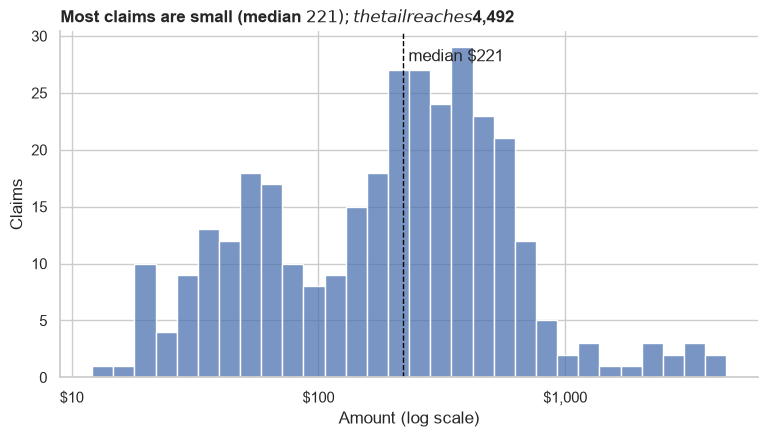

In [4]:
# 4a Style helper + distribution of claim amount (log scale)
DOLLARS = StrMethodFormatter("${x:,.0f}")

def style_axes(
        ax: plt.Axes, title: str, xlabel: str, ylabel: str = ""
) -> None:
    """Apply the notebook chart style: takeaway title, label, no clutter. """
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    sns.despine(ax=ax)

median_amount = claims["amount"].median()
max_amount = claims["amount"].max()

fig, ax = plt.subplots()
sns.histplot(claims, x="amount", bins=30, log_scale=True, ax=ax)
ax.axvline(median_amount, color="black", linestyle="--", linewidth=1)
ax.text(
    median_amount,
    ax.get_ylim()[1] * 0.95,
    f" median ${median_amount:,.0f}",
    va="top",
)
ax.xaxis.set_major_formatter(DOLLARS)
style_axes(
    ax,
    f"Most claims are small (median ${median_amount:,.0f}); "
    f"the tail reaches ${max_amount:,.0f}",
    "Amount (log scale)",
    "Claims",
)
plt.show()

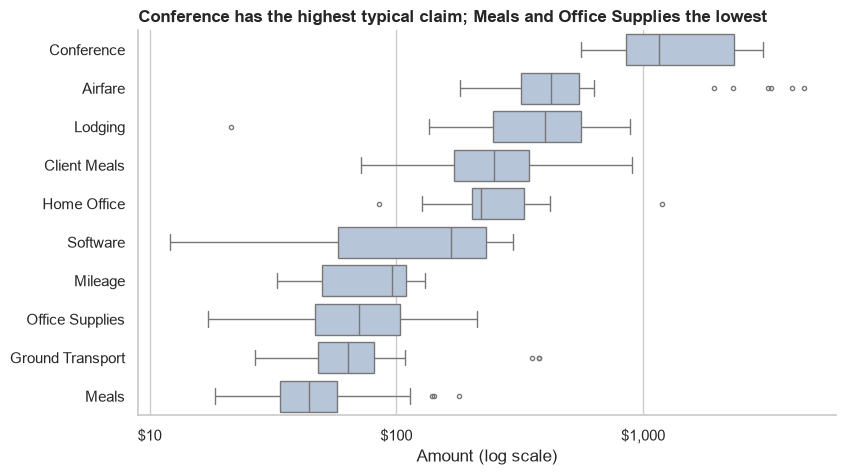

In [5]:
# 4b Amount by category, ordered by median
category_order = (
    claims.groupby("category")["amount"]
    .median()
    .sort_values(ascending=False)
    .index
)
top_category = category_order[0]

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    claims,
    x="amount",
    y="category",
    order=category_order,
    log_scale=True,
    color="lightsteelblue",
    fliersize=3,
    ax=ax,
    )
ax.xaxis.set_major_formatter(DOLLARS)
style_axes(
    ax,
    f"{top_category} has the highest typical claim; "
    "Meals and Office Supplies the lowest",
    "Amount (log scale)",
)
plt.show()

Skipped 3 Lodging incidentals (no nights)


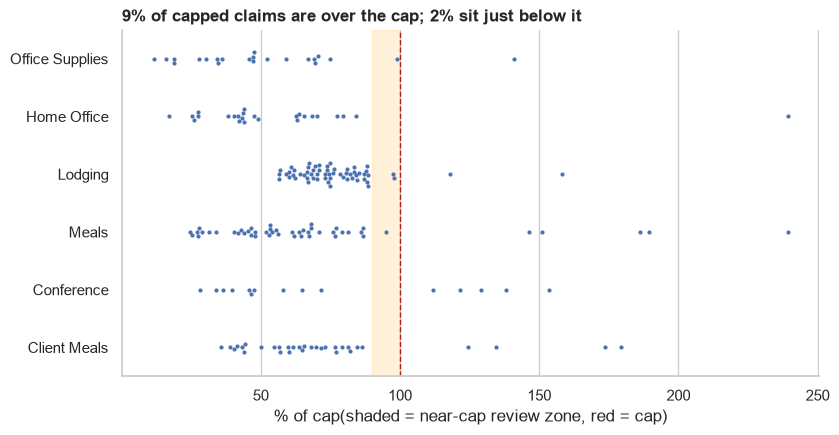

zone,under 90%,near cap (90-100%),over cap,All
category,,,,
Client Meals,28,0,4,32
Conference,10,0,5,15
Home Office,24,0,1,25
Lodging,55,2,2,59
Meals,42,1,5,48
Office Supplies,20,1,1,22
All,179,4,18,201


In [6]:
# 4c Amount as % of its cap for capped categories
NEAR_CAP_START = (1 - POLICY["escalation"]["near_cap_pct"]) * 100
ZONE_LABELS = ["under 90%", "near cap (90-100%)", "over cap"]

def cap_pct(claim: dict) -> float | None:
    """Return the claim's value as a % of its cap, or None if uncapped."""
    usage = cap_usage(claim, POLICY)
    return None if usage is None else usage[0] / usage[1] * 100
capped = claims.assign(
cap_pct=[cap_pct(c) for c in claims.to_dict("records")]
).dropna(subset=["cap_pct"])
capped["zone"] = pd.cut(
    capped["cap_pct"],
    bins=[0, NEAR_CAP_START, 100, float("inf")],
    labels=ZONE_LABELS,
    right=False,
)
zone_share = capped["zone"].value_counts(normalize=True)

# --- checks ---
capped_categories ={
    "Lodging",
    "Meals",
    "Client Meals",
    "Conference",
    "Home Office",
    "Office Supplies",
}
no_cap_basis = claims["category"].eq("Lodging") & claims["nights"].isna()
has_cap = claims["category"].isin(capped_categories) & ~no_cap_basis
assert len(capped) == has_cap.sum(), "Capped claim count"
assert capped["cap_pct"].gt(0).all, "Non-positive cap usage"
assert capped["zone"].notna().all(), "A claim fell outside every zone"
print(f"Skipped {no_cap_basis.sum()} Lodging incidentals (no nights)")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvspan(NEAR_CAP_START, 100, color="orange", alpha=0.15)
ax.axvline(100, color="firebrick", linestyle="--", linewidth=1)
sns.swarmplot(capped, x="cap_pct", y="category", size=3, ax=ax)
style_axes(
    ax,
    f"{zone_share['over cap']:.0%} of capped claims are over the cap; "
    f"{zone_share['near cap (90-100%)']:.0%} sit just below it",
    "% of cap(shaded = near-cap review zone, red = cap)",
)
plt.show()
pd.crosstab(capped["category"], capped["zone"], margins=True)
